# Encoder Layer

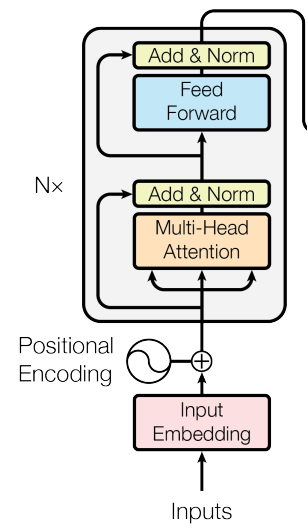

In [1]:
from pathlib import Path
import sys

path = Path("..").resolve()

if str(path) not in sys.path:
    sys.path.append(str(path))

In [2]:
import torch.nn as nn
import torch
from src.model import MultiHeadAttention

c:\Users\Ian Guilherme Dev\Desktop\projetos-pessoais\transformer-scratch\.venv\Lib\site-packages\torch\_subclasses\functional_tensor.py:368: UserWarning: Failed to initialize NumPy: No module named 'numpy' (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:84.)
  cpu = _conversion_method_template(device=torch.device("cpu"))


## Implementação do Position-wise Feed-Forward Networks

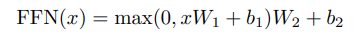

In [3]:
class PositionWiseFFN(nn.Module):
    def __init__(
        self,
        d_model: int,
        d_ff: int,
        dropout
    ):
        
        super().__init__()

        self.model = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Linear(d_ff, d_model)
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.dropout(self.model(x))


In [ ]:
class EncoderLayer(nn.Module):
    def __init__(
            self,
            d_model: int,
            d_ff: int,
            num_heads: int,
            dropout # padrão do paper 2048
        ):

        super().__init__()

        self.mha = MultiHeadAttention(
            d_model=d_model,
            num_heads=num_heads,
            dropout=dropout
        )

        self.ffn = PositionWiseFFN(
            d_model=d_model,
            d_ff=d_ff,
            dropout=dropout
        )

        self.layer_norms = nn.ModuleList([
            nn.LayerNorm(d_model),
            nn.LayerNorm(d_model)
        ])

    def forward(
        self,
        x: torch.Tensor,
        attn_mask: torch.Tensor | None = None
    ):
        
        mha_output = self.mha(x, x, x, attn_mask=attn_mask)
        x = self.layer_norms[0](x + mha_output)

        ffn_output = self.ffn(x)
        x = self.layer_norms[1](x + ffn_output)

        return x


In [ ]:
encoder_layer = EncoderLayer(
    d_model=128,
    d_ff=512,
    num_heads=4,
    dropout=0.1
)

x = torch.randn(2, 5, 128)

output = encoder_layer(x)

print("Entrada:", x.shape)
print("Saída:", output.shape)

Entrada: torch.Size([2, 5, 128])
Saída: torch.Size([2, 5, 128])


# Encoder

Empilhando N camadas do Encoder

In [ ]:
class Encoder(nn.Module):
    def __init__(
        self, 
        d_model:int,
        d_ff:int,
        num_heads:int,
        num_layers=6,
        dropout=0.1
    ):
        
        super().__init__()

        self.layers = nn.ModuleList([
            EncoderLayer(
                d_model=d_model,
                d_ff=d_ff,
                num_heads=num_heads,
                dropout=dropout
            ) for _ in range(num_layers)
        ])

    def forward(
        self,
        x: torch.Tensor,
        attn_mask: torch.Tensor | None = None
    ):

        for layer in self.layers:
            x = layer(x, attn_mask=attn_mask)

        return x

Importante atentar que as EncoderLayers preservam sempre o shape da entrada.

- Multiplas camadas de Encoder são utilizadas pois as representações de cada token são refinadas sucessivamente.

- nn.Module() regista os parametros das camadas contidas nele como do modelo diretamnete, enquanto a lista comum de Python não.
